# Gearbox fault prediction using smartphone audio
**An end-to-end acoustic classification experiment**

**Classes:** normal, tooth fault, bearing fault. This notebook implements the following pipeline:
16 kHz audio → pre-emphasis → 13 MFCC + delta + double delta → CNN-LSTM.
Standalone RNN, GRU, SVM and Gaussian Naive Bayes provide comparisons.

**No experimental recordings were supplied.** The default run generates synthetic
audio solely to verify the software. Its scores are **not experimental gearbox
diagnosis results** or evidence of real-world diagnostic accuracy. Set `DEMO_MODE = False` for real data.

Run cells in order with **Python 3.12**. All pipeline code is contained here;
no private files, credentials, downloaded dataset, or companion Python module is needed.

### Notebook guide

| Part | What you will do |
| --- | --- |
| 1-3: Plan and configure | Understand the experiment, install dependencies and choose data mode |
| 4-6: Prepare audio | Generate/load recordings, isolate groups and extract MFCC sequences |
| 7-9: Train models | Fit CNN-LSTM, RNN, GRU, SVM and Gaussian Naive Bayes |
| 10: Evaluate | Compare held-out recording and segment metrics |
| 11-13: Export and verify | Save models, predict a WAV and run integrity checks |
| 14: Interpret | Understand limitations and plan real experiments |

**Start here:** keep `DEMO_MODE = True` for the included example, then run all cells.
For your own recordings, follow the [README](README.md#use-real-recordings).

## 1. Experimental and implementation methodology

1. **Acquire and label independent recordings.** Record normal, tooth-fault and
   bearing-fault conditions at 300, 500 and 700 RPM. Use a fixed phone, orientation,
   10–15 cm distance, load and recording settings. Record lossless WAV at 44.1 or
   48 kHz if supported. Log session, gearbox identity, speed, load and fault evidence.
   Labels must come from the known inspected condition, not from the audio model.
2. **Define independent groups.** Give all clips from the same acquisition session
   the same `group_id`. For claims about unseen gearboxes, use gearbox identity as
   the group instead. Repeated clips from a continuous recording are not independent.
3. **Split groups before segmentation.** Use approximately 70% train, 15% validation
   and 15% test. A deterministic search finds a group-disjoint allocation containing
   every class, preferring class/speed coverage. Exact ratios may be impossible with
   small group counts. Print and inspect the actual allocation and speed coverage.
4. **Preprocess.** Read WAV, reject silent/nonfinite/too-short audio, downmix to mono,
   resample to 16 kHz and subtract DC. Keep full 2-second windows with a 1-second
   hop. Discard the incomplete tail; report the number of segments. Apply a
   pre-emphasis filter `y[t] = x[t] - 0.97 x[t-1]` independently in each window.
5. **Extract features.** Use 400-sample (25 ms) Hamming frames and a 160-sample
   (10 ms) hop, a 400-point FFT, 40 Mel filters and 13 MFCCs. Stack first and
   second derivatives (9-frame regression windows) into `(198, 39)` sequences.
   Fit feature means and standard deviations using **training frames only**.
6. **Train and select.** Train the specified 64/128-filter Conv1D → 128-unit LSTM
   → dropout 0.3 → Dense(64) → softmax(3) network with Adam 0.001, batch size 32,
   up to 150 epochs. Use validation loss for early stopping and learning-rate
   reduction; restore the best weights. Compare fixed SVM and Gaussian NB baselines
   using each sequence's mean and standard deviation (78 features).
7. **Evaluate once on the held-out test set.** Report accuracy, macro F1, balanced
   accuracy, log loss, per-class precision/recall/F1 and confusion matrices. Show
   segment-level and recording-level scores (average segment probabilities), and
   recording-level scores by RPM. Correlated windows do not increase the number
   of independent experimental trials.
8. **Export and infer.** Save the best model, scalers, class order, feature settings,
   split manifest and metrics. Reload the saved bundle to classify a new WAV using
   exactly the same feature pipeline and averaging rule.

### Methodological considerations

- Frames are not independent labelled training examples: the neural model consumes
  sequences of frames. Ten minutes at a 10 ms hop gives about 60,000 frames, not
  6,000; the number of 2-second examples is much smaller.
- Accuracy must be measured on independent held-out recordings.
- MFCC extraction is a design choice whose usefulness must be measured. No classifier
  is guaranteed to outperform the baselines. CNN temporal filters and the LSTM
  operate within a short clip; this does not establish long-term fault progression.
- A local tooth defect can recur at shaft rotation frequency with gear-mesh modulation;
  tooth-fault diagnosis should not assume every impact occurs at mesh frequency.
- This three-class model assumes a single labelled condition. Unknown and compound
  faults are outside its training scope; softmax scores are not calibrated confidence.

## 2. Setup

From the repository folder, create the environment described in `README.md`, install
`requirements.txt`, and launch JupyterLab with that environment. Choose its Python kernel.
The next cell imports the libraries; installation is intentionally a separate step.

In [1]:
import os

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
import hashlib
import json
import platform
import tempfile
from dataclasses import asdict, dataclass
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import joblib
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import tensorflow as tf
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    log_loss,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

SEED = 42
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
# Small bounded thread pools also work on CPU-only laptops.
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#334155",
        "font.size": 10,
        "savefig.bbox": "tight",
    }
)
pd.set_option("display.max_columns", 12)
print("Python", platform.python_version(), "| TensorFlow", tf.__version__)

Python 3.12.10 | TensorFlow 2.19.0


## 3. Configuration and real-data contract

For real data, create `data/metadata.csv` with columns `path,label,group_id,rpm`.
Paths are relative to `data/`, for example `raw/normal/run01.wav`.
Allowed labels are exactly `normal`, `tooth_fault`, `bearing_fault`.
An example CSV is provided as a **schema illustration**, not a sufficient dataset.
Use multiple independent groups for every class and speed; 10 or more per class/speed
is a useful collection plan, not a guarantee of adequate statistical power.
At least three distinct groups per class are required by the split checks.

If multiple speeds/classes occur in one session, retain the same group ID for all
those recordings. Never manufacture group IDs by chopping one session into files.
The split can keep related data together only if this metadata is correct.

In [2]:
DEMO_MODE = True  # Change to False only after supplying data/metadata.csv.
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUTPUT_DIR = ROOT / "outputs" / ("demo" if DEMO_MODE else "real") / RUN_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CLASSES = ["normal", "tooth_fault", "bearing_fault"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}


@dataclass(frozen=True)
class FeatureConfig:
    """Signal-processing settings saved with every trained model bundle."""

    sample_rate: int = 16000
    segment_seconds: float = 2.0
    segment_hop_seconds: float = 1.0
    frame_length: int = 400
    frame_hop: int = 160
    n_mels: int = 40
    n_mfcc: int = 13
    preemphasis: float = 0.97
    delta_width: int = 9


CFG = FeatureConfig()
MAX_EPOCHS = 3 if DEMO_MODE else 150
BATCH_SIZE = 32
print("SYNTHETIC SOFTWARE DEMO" if DEMO_MODE else "REAL RECORDINGS")
print("Artifacts:", OUTPUT_DIR.relative_to(ROOT))

SYNTHETIC SOFTWARE DEMO
Artifacts: outputs\demo\20261013T011119387318Z


## 4. Optional synthetic demonstration

The artificial classes below differ through deliberately designed tones and pulses.
They are not a validated gearbox simulator. Each generated file is a separate toy
group, and every run uses a fixed seed. The demo writes 90 four-second WAV files
(10 per class/speed), making the entire pipeline runnable without experimental data.

In [3]:
def create_demo_dataset(data_dir, seed=SEED):
    """Create reproducible toy WAVs; these signals do not simulate validated faults."""
    rng = np.random.default_rng(seed)
    folder = data_dir / "demo"
    folder.mkdir(parents=True, exist_ok=True)
    sr = 16000
    t = np.arange(4 * sr) / sr
    rows = []
    for label_id, label in enumerate(CLASSES):
        for rpm in (300, 500, 700):
            for run in range(10):
                f = (rpm / 60) * 24 * rng.uniform(0.96, 1.04)
                phase = rng.uniform(0, 2 * np.pi)
                audio = 0.15 * np.sin(2 * np.pi * f * t + phase)
                audio += 0.06 * np.sin(2 * np.pi * 2 * f * t)
                audio += rng.normal(0, 0.035, len(t))
                if label_id == 1:
                    pulses = np.maximum(0, np.sin(2 * np.pi * rpm / 60 * t)) ** 18
                    audio += 0.22 * pulses * np.sin(2 * np.pi * 1800 * t)
                elif label_id == 2:
                    pulses = np.maximum(0, np.sin(2 * np.pi * 3.6 * rpm / 60 * t)) ** 10
                    audio += 0.19 * pulses * np.sin(2 * np.pi * 3300 * t)
                audio *= rng.uniform(0.7, 1.2)
                name = f"{label}_{rpm}_{run:02d}"
                file = folder / f"{name}.wav"
                sf.write(file, audio, sr, subtype="PCM_16")
                rows.append(
                    dict(path=f"demo/{name}.wav", label=label, group_id=name, rpm=rpm)
                )
    metadata = pd.DataFrame(rows)
    metadata.to_csv(folder / "metadata.csv", index=False)
    return metadata


if DEMO_MODE:
    manifest = create_demo_dataset(DATA_DIR)
else:
    metadata_path = DATA_DIR / "metadata.csv"
    if not metadata_path.is_file():
        raise FileNotFoundError("Add data/metadata.csv and your WAV recordings first.")
    manifest = pd.read_csv(metadata_path, dtype={"group_id": str})

## 5. Validate recordings and allocate groups

Exact duplicate decoded waveforms are rejected even if filenames differ. Edited or
partially overlapping copies require correct group metadata and cannot be reliably
identified by a simple hash. Split selection uses labels, RPM and group counts only,
never audio features or model test scores. Missing speed/class coverage is reported.

In [4]:
def validate_manifest(frame, data_dir):
    """Check metadata, audio quality and duplicates before allocating recordings."""
    required = ["path", "label", "group_id", "rpm"]
    if not set(required).issubset(frame.columns):
        raise ValueError(f"Metadata must contain {required}")
    frame = frame.copy().reset_index(drop=True)
    if frame.empty or frame[required].isna().any().any():
        raise ValueError("Metadata is empty or has missing values.")
    for col in ("path", "label", "group_id"):
        frame[col] = frame[col].astype(str).str.strip()
        if frame[col].eq("").any():
            raise ValueError(f"Blank {col} values are not allowed.")
    if set(frame.label) != set(CLASSES):
        raise ValueError(f"Data must contain exactly these labels: {CLASSES}")
    frame["rpm"] = pd.to_numeric(frame.rpm, errors="raise")
    if not np.isfinite(frame.rpm).all() or (frame.rpm <= 0).any():
        raise ValueError("RPM must be finite and positive.")
    resolved = []
    hashes, durations, clipping = [], [], []
    root = data_dir.resolve()
    for row in frame.itertuples():
        file = (root / row.path).resolve()
        if not file.is_relative_to(root) or file.suffix.lower() != ".wav":
            raise ValueError(f"Use a WAV path within data/: {row.path}")
        if not file.is_file():
            raise FileNotFoundError(file)
        audio, sr = sf.read(file, dtype="float32", always_2d=True)
        if len(audio) / sr < CFG.segment_seconds:
            raise ValueError(
                f"Recording shorter than {CFG.segment_seconds}s: {row.path}"
            )
        if not np.isfinite(audio).all():
            raise ValueError(f"Nonfinite audio: {row.path}")
        mono = audio.mean(axis=1)
        if np.std(mono) < 1e-7:
            raise ValueError(f"Silent or constant mono audio: {row.path}")
        hashes.append(hashlib.sha256(str(sr).encode() + audio.tobytes()).hexdigest())
        durations.append(len(audio) / sr)
        clipping.append(float(np.mean(np.abs(audio) >= 0.999)))
        resolved.append(str(file))
    if len(set(resolved)) != len(resolved) or len(set(hashes)) != len(hashes):
        raise ValueError(
            "Duplicate recordings found; remove duplicates before splitting."
        )
    frame["audio_sha256"] = hashes
    frame["duration_seconds"] = durations
    frame["clipped_fraction"] = clipping
    frame["recording_id"] = np.arange(len(frame))
    counts = frame.groupby("label").group_id.nunique()
    if (counts < 3).any():
        raise ValueError(
            f"Need at least 3 independent groups per class: {counts.to_dict()}"
        )
    if (frame.clipped_fraction > 0.01).any():
        print("Review recordings with >1% near-full-scale samples:")
        display(frame.loc[frame.clipped_fraction > 0.01, ["path", "clipped_fraction"]])
    return frame


def grouped_split(frame, seed=SEED, attempts=600):
    """Select an approximately 70/15/15 split without sharing acquisition groups."""
    # GroupShuffleSplit fractions concern groups; score also considers recording counts.
    target = np.array([0.70, 0.15, 0.15])
    expected = set(zip(frame.label, frame.rpm))
    best = None
    outer = GroupShuffleSplit(n_splits=attempts, test_size=0.15, random_state=seed)
    for attempt, (trainval, test) in enumerate(
        outer.split(frame, groups=frame.group_id)
    ):
        subset = frame.iloc[trainval]
        inner = GroupShuffleSplit(
            n_splits=1, test_size=0.15 / 0.85, random_state=seed + attempt + 1
        )
        try:
            tr, va = next(inner.split(subset, groups=subset.group_id))
        except ValueError:
            continue
        parts = [trainval[tr], trainval[va], test]
        if any(set(frame.iloc[p].label) != set(CLASSES) for p in parts):
            continue
        missing = sum(
            len(expected - set(zip(frame.iloc[p].label, frame.iloc[p].rpm)))
            for p in parts
        )
        ratio_error = np.abs(
            np.array([len(p) for p in parts]) / len(frame) - target
        ).sum()
        score = 10 * missing + ratio_error
        if best is None or score < best[0]:
            best = (score, parts)
    if best is None:
        raise ValueError(
            "No valid three-way group split found. Collect more independent groups "
            "or review grouping; do not split individual windows to bypass this."
        )
    result = frame.copy()
    for name, indices in zip(("train", "validation", "test"), best[1]):
        result.loc[indices, "split"] = name
    assert result.groupby("group_id").split.nunique().max() == 1
    for name in ("train", "validation", "test"):
        part = result[result.split == name]
        missing = expected - set(zip(part.label, part.rpm))
        if missing:
            print(f"WARNING: {name} has no recordings for {sorted(missing)}")
    return result

### Inspect the split

Review group counts and class/speed coverage before extracting features.

In [5]:
manifest = grouped_split(validate_manifest(manifest, DATA_DIR))
manifest.to_csv(OUTPUT_DIR / "recording_split.csv", index=False)
display(pd.crosstab([manifest.label, manifest.rpm], manifest.split))
display(
    manifest.groupby("split").agg(
        recordings=("path", "size"),
        independent_groups=("group_id", "nunique"),
        seconds=("duration_seconds", "sum"),
    )
)

split              test  train  validation
label         rpm                         
bearing_fault 300     1      6           3
              500     3      6           1
              700     2      6           2
normal        300     1      8           1
              500     1      8           1
              700     1      7           2
tooth_fault   300     1      7           2
              500     3      6           1
              700     1      8           1

,recordings,independent_groups,seconds
split,,,
test,14,14,56.0
train,62,62,248.0
validation,14,14,56.0


## 6. Audio loading, segmentation and feature extraction

Downmix before MFCC extraction so channel loudness does not change its behavior.
Centering of FFT frames is disabled: only complete frames are used. At the configured
length, each 2-second window has `1 + floor((32000 - 400)/160) = 198` frames.
All full windows are retained, including quiet windows within otherwise valid audio.
No augmentation or denoising is applied without validation evidence that it helps.

In [6]:
def load_audio(path, cfg):
    """Read a WAV as mono float32, resample it and remove its DC offset."""
    audio, sr = sf.read(path, dtype="float32", always_2d=True)
    audio = audio.mean(axis=1)
    if not np.isfinite(audio).all() or len(audio) == 0:
        raise ValueError(f"Empty or invalid audio: {path}")
    if sr != cfg.sample_rate:
        audio = librosa.resample(audio, orig_sr=sr, target_sr=cfg.sample_rate)
    audio = audio - np.mean(audio)
    if np.std(audio) < 1e-7:
        raise ValueError(f"Silent/constant audio after mono conversion: {path}")
    return audio.astype(np.float32)


def segment_audio(audio, cfg):
    """Yield start times and full fixed-length windows, discarding the tail."""
    length = round(cfg.segment_seconds * cfg.sample_rate)
    hop = round(cfg.segment_hop_seconds * cfg.sample_rate)
    if len(audio) < length:
        raise ValueError(f"Need at least {cfg.segment_seconds} seconds of audio.")
    for start in range(0, len(audio) - length + 1, hop):
        yield start / cfg.sample_rate, audio[start : start + length]


def extract_features(segment, cfg):
    """Return a time-by-feature matrix of MFCC, delta and delta-delta values."""
    emphasized = np.concatenate(
        [segment[:1], segment[1:] - cfg.preemphasis * segment[:-1]]
    )
    mfcc = librosa.feature.mfcc(
        y=emphasized,
        sr=cfg.sample_rate,
        n_mfcc=cfg.n_mfcc,
        n_mels=cfg.n_mels,
        n_fft=cfg.frame_length,
        win_length=cfg.frame_length,
        hop_length=cfg.frame_hop,
        window="hamming",
        center=False,
    )
    delta = librosa.feature.delta(mfcc, width=cfg.delta_width, order=1)
    delta2 = librosa.feature.delta(mfcc, width=cfg.delta_width, order=2)
    features = np.concatenate([mfcc, delta, delta2], axis=0).T.astype(np.float32)
    if not np.isfinite(features).all():
        raise ValueError("Nonfinite MFCC features.")
    return features


def prepare_dataset(frame, data_dir, cfg):
    """Extract sequences and retain recording provenance for every window."""
    features, rows = [], []
    for row in frame.itertuples():
        audio = load_audio(data_dir / row.path, cfg)
        for start, segment in segment_audio(audio, cfg):
            features.append(extract_features(segment, cfg))
            rows.append(
                dict(
                    recording_id=row.recording_id,
                    group_id=row.group_id,
                    path=row.path,
                    label=row.label,
                    rpm=row.rpm,
                    split=row.split,
                    start_seconds=start,
                    target=CLASS_TO_ID[row.label],
                )
            )
    return np.stack(features), pd.DataFrame(rows)

### Prepare and normalize sequences

Only training frames contribute to the scaler statistics.

In [7]:
X, windows = prepare_dataset(manifest, DATA_DIR, CFG)
y = windows.target.to_numpy(dtype=np.int64)
windows.to_csv(OUTPUT_DIR / "segment_manifest.csv", index=False)
indices = {
    name: np.flatnonzero(windows.split.eq(name))
    for name in ("train", "validation", "test")
}
train_idx, val_idx, test_idx = (indices[n] for n in ("train", "validation", "test"))
feature_scaler = StandardScaler().fit(X[train_idx].reshape(-1, X.shape[-1]))
X_scaled = (
    feature_scaler.transform(X.reshape(-1, X.shape[-1]))
    .reshape(X.shape)
    .astype(np.float32)
)
print("Feature tensor:", X.shape, "(segments, frames, features)")
print("Feature tensor memory (MiB):", round(X.nbytes / 2**20, 2))
display(windows.groupby(["split", "label"]).size().unstack(fill_value=0))
assert X.shape[2] == 39
assert set(windows.iloc[train_idx].group_id).isdisjoint(windows.iloc[test_idx].group_id)
assert np.isfinite(X_scaled).all()

Feature tensor: (270, 198, 39) (segments, frames, features)
Feature tensor memory (MiB): 7.95


label,bearing_fault,normal,tooth_fault
split,,,
test,18,9,15
train,54,69,63
validation,18,12,12


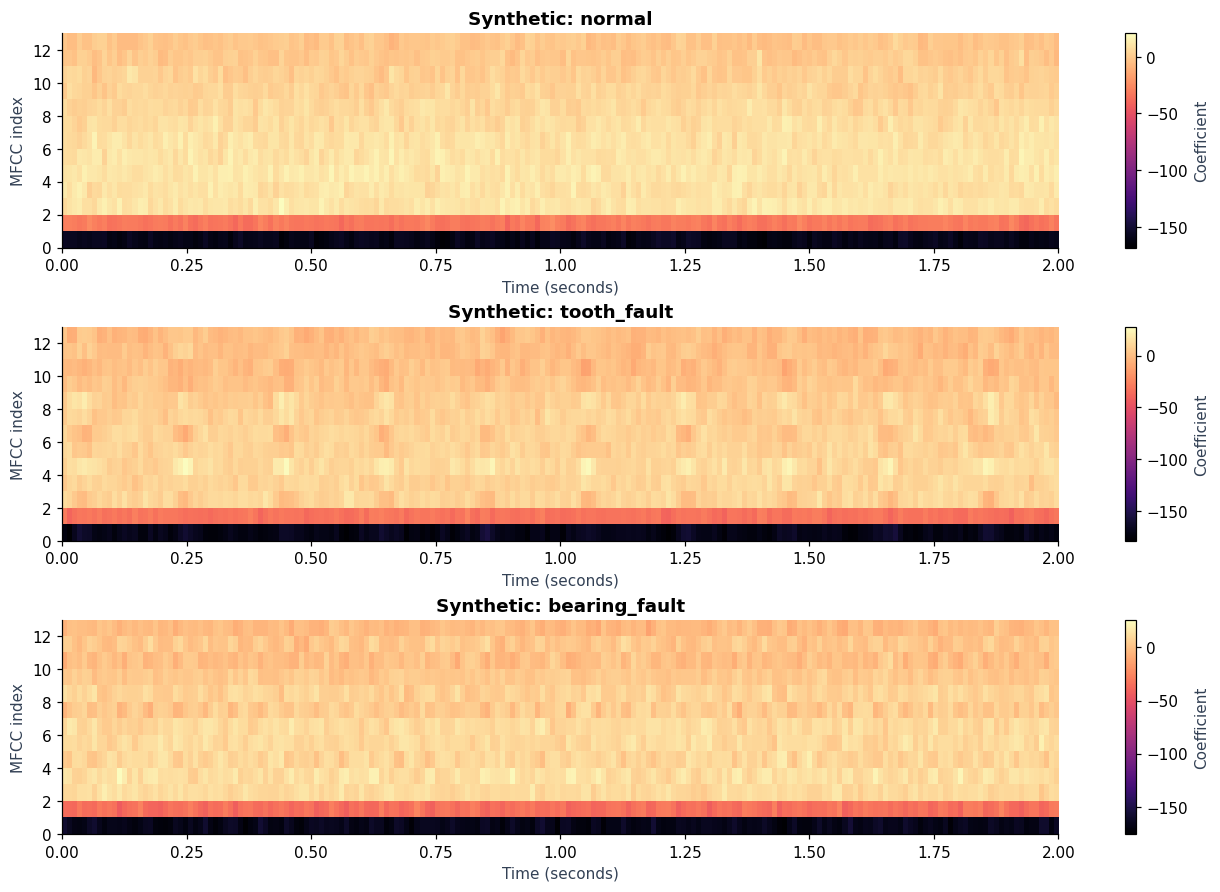

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8), constrained_layout=True)
for ax, label in zip(axes, CLASSES):
    i = windows.index[(windows.label == label) & (windows.split == "train")][0]
    im = ax.imshow(
        X[i, :, :13].T,
        aspect="auto",
        origin="lower",
        cmap="magma",
        extent=[0, CFG.segment_seconds, 0, 13],
    )
    ax.set(
        title=f"{'Synthetic' if DEMO_MODE else 'Recorded'}: {label}",
        xlabel="Time (seconds)",
        ylabel="MFCC index",
    )
    fig.colorbar(im, ax=ax, label="Coefficient")
fig.savefig(OUTPUT_DIR / "mfcc_examples.png", dpi=150)
plt.show()

## 7. CNN-LSTM model and training

The two convolution blocks preserve time with same padding and pool by two, producing
198 → 99 → 49 time steps before the LSTM. Sparse categorical cross-entropy uses integer
labels and is equivalent to categorical cross-entropy with one-hot targets here.
The default synthetic run uses only three epochs as a software check. Real-data mode
allows 150 epochs. Validation loss controls stopping; test data is never used in fit.

In [9]:
def build_model(input_shape, num_classes):
    """Compile the project CNN-LSTM architecture with the shared optimizer."""
    model = tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=input_shape),
            tf.keras.layers.Conv1D(64, 3, padding="same", activation="relu"),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.MaxPooling1D(2),
            tf.keras.layers.Conv1D(128, 3, padding="same", activation="relu"),
            tf.keras.layers.BatchNormalization(),
            tf.keras.layers.MaxPooling1D(2),
            tf.keras.layers.LSTM(128),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(64, activation="relu"),
            tf.keras.layers.Dense(num_classes, activation="softmax"),
        ],
        name="gearbox_cnn_lstm",
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def make_dataset(ids, training=False):
    """Batch selected windows; shuffle only the training partition."""
    dataset = tf.data.Dataset.from_tensor_slices((X_scaled[ids], y[ids]))
    if training:
        dataset = dataset.shuffle(len(ids), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 2
    options.experimental_deterministic = True
    return dataset.batch(BATCH_SIZE).with_options(options).prefetch(1)


def train_neural_model(network, checkpoint_name, history_name):
    """Fit on training windows and reload the lowest-validation-loss checkpoint."""
    checkpoint = OUTPUT_DIR / checkpoint_name
    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=15, restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", patience=5, factor=0.5, min_lr=1e-6
        ),
        tf.keras.callbacks.ModelCheckpoint(
            str(checkpoint), monitor="val_loss", save_best_only=True
        ),
        tf.keras.callbacks.CSVLogger(str(OUTPUT_DIR / history_name)),
        tf.keras.callbacks.TerminateOnNaN(),
    ]
    fitted = network.fit(
        make_dataset(train_idx, training=True),
        validation_data=make_dataset(val_idx),
        epochs=MAX_EPOCHS,
        callbacks=callbacks,
        shuffle=False,  # Training dataset already performs seeded shuffling.
        verbose=2,
    )
    return tf.keras.models.load_model(checkpoint), fitted.history

### Train the CNN-LSTM

Checkpoints are selected by validation loss. Test recordings are used only later.

In [10]:
model = build_model(X.shape[1:], len(CLASSES))
model.summary()
model, cnn_history = train_neural_model(model, "cnn_lstm.keras", "training_history.csv")

Model: "gearbox_cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 198, 64)        │         7,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 198, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 99, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 99, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 99, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 49, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 173,059 (676.01 KB)

 Trainable params: 172,675 (674.51 KB)

 Non-trainable params: 384 (1.50 KB)

...

6/6 - 3s - 470ms/step - accuracy: 0.6344 - loss: 0.8711 - val_accuracy: 0.2857 - val_loss: 1.0641 - learning_rate: 0.0010


Epoch 2/3


6/6 - 0s - 47ms/step - accuracy: 0.9946 - loss: 0.2749 - val_accuracy: 0.6429 - val_loss: 1.1050 - learning_rate: 0.0010


Epoch 3/3


6/6 - 0s - 43ms/step - accuracy: 1.0000 - loss: 0.0663 - val_accuracy: 0.7143 - val_loss: 1.2968 - learning_rate: 0.0010


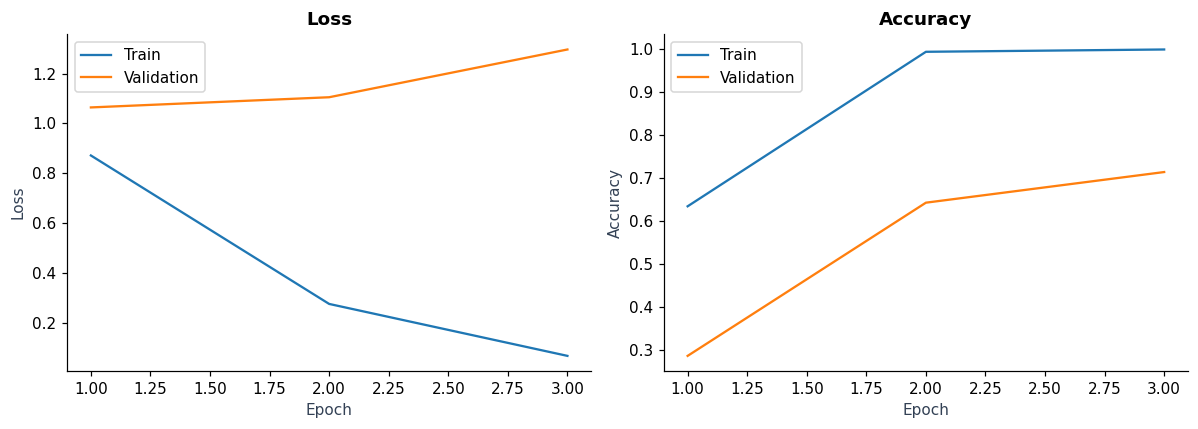

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(
        np.arange(1, len(cnn_history[metric]) + 1), cnn_history[metric], label="Train"
    )
    ax.plot(
        np.arange(1, len(cnn_history[metric]) + 1),
        cnn_history["val_" + metric],
        label="Validation",
    )
    ax.set(xlabel="Epoch", ylabel=metric.capitalize(), title=metric.capitalize())
    ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "training_curves.png", dpi=150)
plt.show()

## 8. Standalone RNN and GRU comparison

Both models consume the same normalized `(198, 39)` sequences directly, with no
convolution layers. Each uses 128 recurrent units, dropout 0.3, Dense(64, ReLU)
and three softmax outputs. RNN means Keras `SimpleRNN` (tanh); GRU uses the Keras
default gated recurrent unit. They share the CNN-LSTM split, training-only scaler,
Adam learning rate, batch size, epoch limit and validation-loss checkpoint rule.
Reset the random seed before each model. Parameter counts differ, so this is a
comparison with the same epoch budget, not matched computational cost. Three demo
epochs do not establish which architecture performs best after convergence.

Model: "gearbox_rnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        21,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,955 (117.01 KB)

 Trainable params: 29,955 (117.01 KB)

 Non-trainable params: 0 (0.00 B)

...

6/6 - 2s - 360ms/step - accuracy: 0.4140 - loss: 1.1484 - val_accuracy: 0.5238 - val_loss: 1.0035 - learning_rate: 0.0010


Epoch 2/3


6/6 - 0s - 69ms/step - accuracy: 0.7258 - loss: 0.8426 - val_accuracy: 0.6905 - val_loss: 0.8348 - learning_rate: 0.0010


Epoch 3/3


6/6 - 0s - 66ms/step - accuracy: 0.8548 - loss: 0.6511 - val_accuracy: 0.7857 - val_loss: 0.6642 - learning_rate: 0.0010


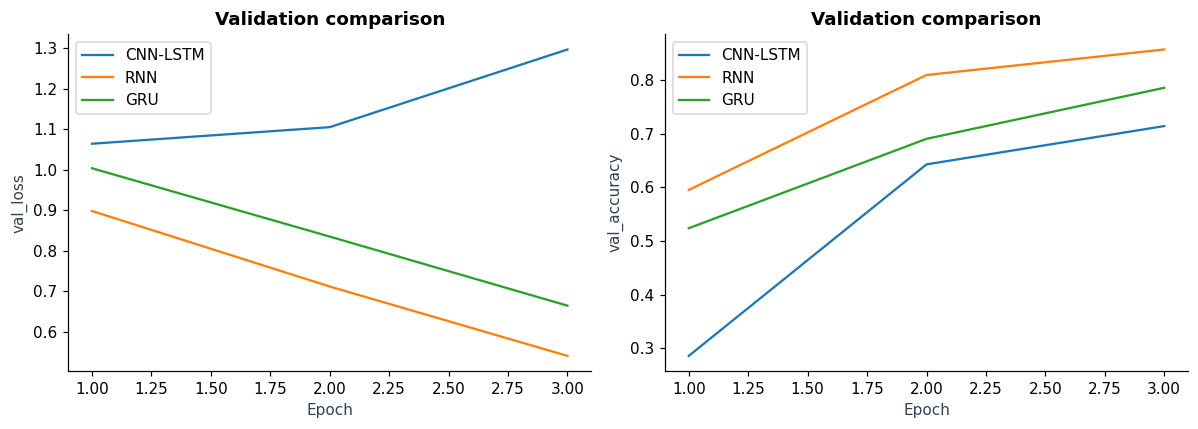

In [12]:
neural_models = {"CNN-LSTM": model}
neural_histories = {"CNN-LSTM": cnn_history}
model_files = {"CNN-LSTM": "cnn_lstm.keras", "RNN": "RNN.keras", "GRU": "GRU.keras"}


def build_recurrent_model(kind, input_shape, num_classes):
    """Compile a standalone SimpleRNN or GRU with the common classifier head."""
    recurrent_layer = {"RNN": tf.keras.layers.SimpleRNN, "GRU": tf.keras.layers.GRU}[
        kind
    ]
    network = tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=input_shape),
            recurrent_layer(128),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(64, activation="relu"),
            tf.keras.layers.Dense(num_classes, activation="softmax"),
        ],
        name=f"gearbox_{kind.lower()}",
    )
    network.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return network


for name in ("RNN", "GRU"):
    tf.keras.utils.set_random_seed(SEED)
    network = build_recurrent_model(name, X.shape[1:], len(CLASSES))
    network.summary()
    neural_models[name], neural_histories[name] = train_neural_model(
        network, model_files[name], f"{name}_training_history.csv"
    )

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, values in neural_histories.items():
    for ax, metric in zip(axes, ["val_loss", "val_accuracy"]):
        ax.plot(np.arange(1, len(values[metric]) + 1), values[metric], label=name)
        ax.set(xlabel="Epoch", ylabel=metric, title="Validation comparison")
        ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "neural_validation_comparison.png", dpi=150)
plt.show()

## 9. Baseline classifiers

Each baseline sees a 78-value vector: the mean and standard deviation of all 39
features over a segment. SVM uses a linear decision function (`C=1`) and training-only
standardization. Its decision scores are converted to normalized exponential scores
for aggregation; these are **uncalibrated**, and SVM log loss should be interpreted
with that limitation. This avoids hidden, window-level probability-calibration folds.
Gaussian NB uses the same standardized summary features. No test-set tuning is done.

In [13]:
def summarize_features(features):
    """Reduce each sequence to 39 means and 39 standard deviations."""
    return np.concatenate([features.mean(axis=1), features.std(axis=1)], axis=1)


summary_features = summarize_features(X)
baselines = {
    "SVM": make_pipeline(
        StandardScaler(), SVC(kernel="linear", C=1.0, decision_function_shape="ovr")
    ),
    "GaussianNB": make_pipeline(StandardScaler(), GaussianNB(var_smoothing=1e-9)),
}
for name, classifier in baselines.items():
    classifier.fit(summary_features[train_idx], y[train_idx])
    joblib.dump(classifier, OUTPUT_DIR / f"{name}.joblib")


def baseline_probabilities(classifier, features):
    """Return class probabilities, or uncalibrated normalized SVM scores."""
    if hasattr(classifier, "predict_proba"):
        return classifier.predict_proba(features)
    scores = classifier.decision_function(features)
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)

## 10. Held-out evaluation

The following outputs are generated by actual execution. In demo mode every plot and
table refers to synthetic data. Averaging window scores gives one prediction per
recording, but several recordings in one group still are not independent trials.
If the model or hyperparameters are changed after inspecting this test set, collect
a fresh holdout for the final performance claim. Compare RPM results only where
there are enough independent test recordings.

In [14]:
def neural_probabilities(network, features, batch_size=32):
    """Compute inference scores in bounded batches without training-time dropout."""
    return np.concatenate(
        [
            network(features[i : i + batch_size], training=False).numpy()
            for i in range(0, len(features), batch_size)
        ]
    )


def metric_values(target, probabilities):
    """Compute classification metrics in the fixed project class order."""
    predicted = probabilities.argmax(axis=1)
    return dict(
        accuracy=float(accuracy_score(target, predicted)),
        balanced_accuracy=float(balanced_accuracy_score(target, predicted)),
        macro_f1=float(
            f1_score(
                target,
                predicted,
                labels=range(len(CLASSES)),
                average="macro",
                zero_division=0,
            )
        ),
        log_loss=float(log_loss(target, probabilities, labels=range(len(CLASSES)))),
    )


def recording_predictions(segment_metadata, probabilities):
    """Average window scores into a single prediction per source recording."""
    table = (
        segment_metadata[["recording_id", "group_id", "path", "rpm", "target"]]
        .reset_index(drop=True)
        .copy()
    )
    for i, label in enumerate(CLASSES):
        table[label] = probabilities[:, i]
    return table.groupby(
        ["recording_id", "group_id", "path", "rpm", "target"], as_index=False
    )[CLASSES].mean()

### Compare all five models

The next cell evaluates the same held-out recordings for every model.

SYNTHETIC DEMO SCORES — NOT REAL FAULT-DETECTION PERFORMANCE


model,level,synthetic,count,accuracy,balanced_accuracy,macro_f1,log_loss
CNN-LSTM,segment,True,42,35.71%,33.33%,0.175,0.900
CNN-LSTM,recording,True,14,35.71%,33.33%,0.175,0.900
RNN,segment,True,42,85.71%,83.70%,0.829,0.439
RNN,recording,True,14,92.86%,93.33%,0.915,0.398
GRU,segment,True,42,88.10%,85.93%,0.855,0.536
GRU,recording,True,14,92.86%,93.33%,0.915,0.523
SVM,segment,True,42,100.00%,100.00%,1.000,0.301
SVM,recording,True,14,100.00%,100.00%,1.000,0.301
GaussianNB,segment,True,42,100.00%,100.00%,1.000,0.000
GaussianNB,recording,True,14,100.00%,100.00%,1.000,0.000


,precision,recall,f1-score,support
normal,0.0000,0.0000,0.0000,3.0000
tooth_fault,0.3571,1.0000,0.5263,5.0000
bearing_fault,0.0000,0.0000,0.0000,6.0000
accuracy,0.3571,0.3571,0.3571,0.3571
macro avg,0.1190,0.3333,0.1754,14.0000
weighted avg,0.1276,0.3571,0.1880,14.0000


,model,rpm,recordings,accuracy
0,CNN-LSTM,300,3,0.3333
1,CNN-LSTM,500,7,0.4286
2,CNN-LSTM,700,4,0.2500
3,RNN,300,3,0.6667
4,RNN,500,7,1.0000
5,RNN,700,4,1.0000
6,GRU,300,3,0.6667
7,GRU,500,7,1.0000
8,GRU,700,4,1.0000
9,SVM,300,3,1.0000


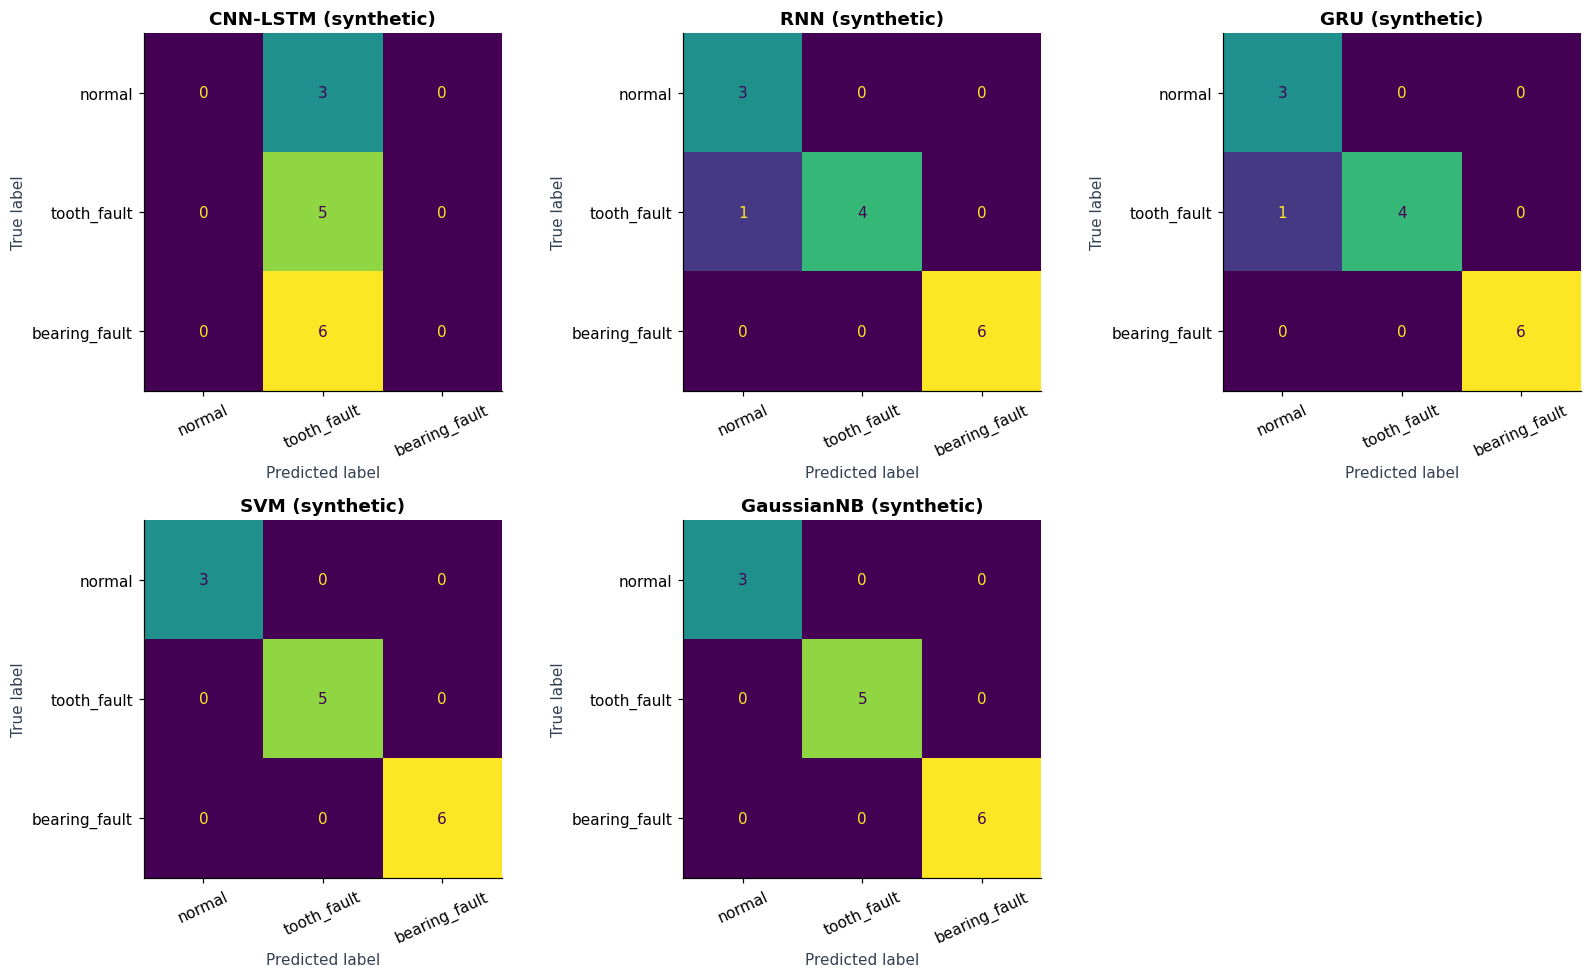

In [15]:
probabilities = {
    name: neural_probabilities(network, X_scaled[test_idx])
    for name, network in neural_models.items()
}
probabilities.update(
    {
        name: baseline_probabilities(clf, summary_features[test_idx])
        for name, clf in baselines.items()
    }
)
records, score_rows, reports, rpm_rows = {}, [], {}, []
for name, prob in probabilities.items():
    assert prob.shape == (len(test_idx), len(CLASSES))
    assert np.allclose(prob.sum(axis=1), 1, atol=1e-5)
    rec = recording_predictions(windows.iloc[test_idx], prob)
    records[name] = rec
    rec.to_csv(OUTPUT_DIR / f"{name}_recording_predictions.csv", index=False)
    for level, target, pred_prob in [
        ("segment", y[test_idx], prob),
        ("recording", rec.target.to_numpy(), rec[CLASSES].to_numpy()),
    ]:
        score_rows.append(
            dict(
                model=name,
                level=level,
                synthetic=DEMO_MODE,
                count=len(target),
                **metric_values(target, pred_prob),
            )
        )
        reports[f"{name}_{level}"] = classification_report(
            target,
            pred_prob.argmax(axis=1),
            labels=range(len(CLASSES)),
            target_names=CLASSES,
            output_dict=True,
            zero_division=0,
        )
    for rpm, group in rec.groupby("rpm"):
        rpm_rows.append(
            dict(
                model=name,
                rpm=rpm,
                recordings=len(group),
                accuracy=accuracy_score(
                    group.target, group[CLASSES].to_numpy().argmax(axis=1)
                ),
            )
        )

scores = pd.DataFrame(score_rows)
scores.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
pd.DataFrame(rpm_rows).to_csv(OUTPUT_DIR / "metrics_by_rpm.csv", index=False)
(OUTPUT_DIR / "classification_reports.json").write_text(
    json.dumps(reports, indent=2), encoding="utf-8"
)
print(
    "SYNTHETIC DEMO SCORES — NOT REAL FAULT-DETECTION PERFORMANCE"
    if DEMO_MODE
    else "Held-out real recording scores"
)
display(
    scores.style.format(
        {
            "accuracy": "{:.2%}",
            "balanced_accuracy": "{:.2%}",
            "macro_f1": "{:.3f}",
            "log_loss": "{:.3f}",
        }
    ).hide(axis="index")
)
display(pd.DataFrame(reports["CNN-LSTM_recording"]).T.round(4))
display(pd.DataFrame(rpm_rows).round(4))
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, rec) in zip(axes.flat, records.items()):
    ConfusionMatrixDisplay.from_predictions(
        rec.target,
        rec[CLASSES].to_numpy().argmax(axis=1),
        labels=range(len(CLASSES)),
        display_labels=CLASSES,
        ax=ax,
        colorbar=False,
        xticks_rotation=25,
    )
    ax.set_title(name + (" (synthetic)" if DEMO_MODE else ""))
for ax in list(axes.flat)[len(records) :]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "recording_confusion_matrices.png", dpi=150)
plt.show()

### Recording-level comparison at a glance

Accuracy counts correct recordings; macro F1 gives each class equal weight.
The chart reflects this run only. Synthetic data and a three-epoch budget cannot
establish real-world model superiority.

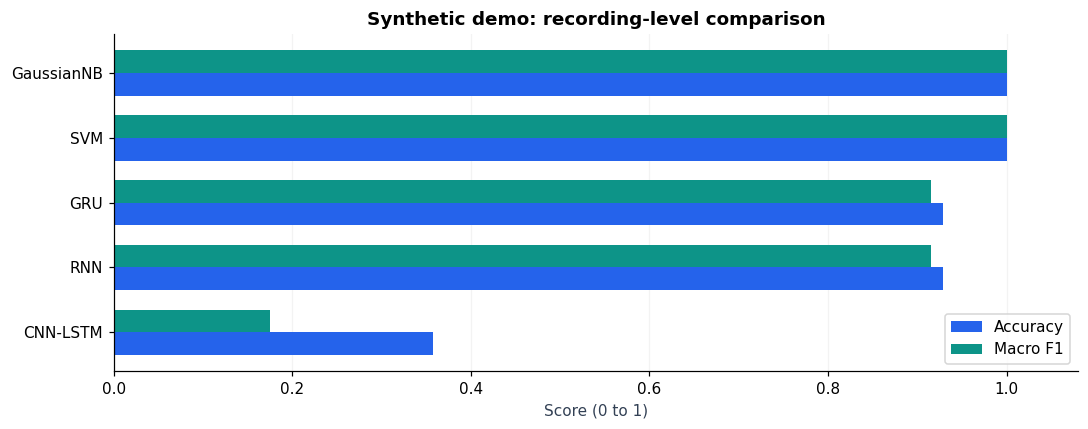

In [16]:
recording_scores = scores[scores.level.eq("recording")].set_index("model")
fig, ax = plt.subplots(figsize=(10, 4))
recording_scores[["accuracy", "macro_f1"]].plot.barh(
    ax=ax, color=["#2563eb", "#0d9488"], width=0.7
)
ax.set(
    xlim=(0, 1.08),
    xlabel="Score (0 to 1)",
    ylabel="",
    title="Synthetic demo: recording-level comparison"
    if DEMO_MODE
    else "Held-out recordings: model comparison",
)
ax.legend(["Accuracy", "Macro F1"], loc="lower right")
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "model_comparison.png", dpi=150)
plt.show()

## 11. Save a reproducible inference bundle

Every run receives a separate output folder. Keep model and preprocessing artifacts
together. The run metadata records the synthetic flag, software versions, random seed,
class order and feature settings. The manifest includes hashes for dataset auditing.
Only load `.joblib` or model artifacts that you trust.

In [17]:
joblib.dump(feature_scaler, OUTPUT_DIR / "feature_scaler.joblib")
run_metadata = {
    "synthetic": DEMO_MODE,
    "seed": SEED,
    "classes": CLASSES,
    "feature_config": asdict(CFG),
    "input_shape": list(X.shape[1:]),
    "max_epochs": MAX_EPOCHS,
    "epochs_run": len(cnn_history["loss"]),
    "best_epoch": int(np.argmin(cnn_history["val_loss"]) + 1),
    "model_files": model_files,
    "neural_training": {
        name: {
            "epochs_run": len(values["loss"]),
            "best_epoch": int(np.argmin(values["val_loss"]) + 1),
            "parameters": neural_models[name].count_params(),
        }
        for name, values in neural_histories.items()
    },
    "aggregation": "arithmetic mean of segment probabilities per recording",
    "python": platform.python_version(),
    "packages": {
        name: version(name)
        for name in [
            "numpy",
            "pandas",
            "scipy",
            "librosa",
            "soundfile",
            "scikit-learn",
            "tensorflow",
            "matplotlib",
            "joblib",
        ]
    },
}
(OUTPUT_DIR / "run_metadata.json").write_text(
    json.dumps(run_metadata, indent=2), encoding="utf-8"
)
with (OUTPUT_DIR / "model_summary.txt").open("w", encoding="utf-8") as handle:
    model.summary(print_fn=lambda line: handle.write(line + "\n"))
print(
    "Saved model, preprocessing, reports, plots and split manifests to",
    OUTPUT_DIR.relative_to(ROOT),
)

Saved model, preprocessing, reports, plots and split manifests to outputs\demo\20261013T011119387318Z


## 12. Predict a new WAV after reloading the saved model

The function uses feature settings and class order from the saved bundle. In a fresh
kernel, run the imports and the `FeatureConfig`, `load_audio`, `segment_audio`,
`extract_features` and `neural_probabilities` definitions, then this cell. Training is
not required to reuse an existing bundle. The example below reuses one held-out
recording to verify reloading; it is not a new independent evaluation.

To use your own audio, call `predict_wav(Path("path/to/new_recording.wav"), bundle_dir)`
with a bundle trained on real recordings. A returned class is the best of the three
known classes; low quality or unfamiliar audio is not automatically rejected.

In [18]:
def predict_wav(audio_path, bundle_dir, model_name="CNN-LSTM"):
    """Reload a neural model and its preprocessing bundle to classify a WAV."""
    bundle_dir = Path(bundle_dir)
    metadata = json.loads(
        (bundle_dir / "run_metadata.json").read_text(encoding="utf-8")
    )
    cfg = FeatureConfig(**metadata["feature_config"])
    classes = metadata["classes"]
    files = metadata.get("model_files", {"CNN-LSTM": "cnn_lstm.keras"})
    if model_name not in files:
        raise ValueError(
            f"Unknown neural model: {model_name}. Choose from {list(files)}"
        )
    network = tf.keras.models.load_model(bundle_dir / files[model_name])
    scaler = joblib.load(bundle_dir / "feature_scaler.joblib")
    audio = load_audio(audio_path, cfg)
    features = np.stack(
        [extract_features(segment, cfg) for _, segment in segment_audio(audio, cfg)]
    )
    if list(features.shape[1:]) != metadata["input_shape"]:
        raise ValueError("Features do not match the saved model input shape.")
    normalized = (
        scaler.transform(features.reshape(-1, features.shape[-1]))
        .reshape(features.shape)
        .astype(np.float32)
    )
    segment_probabilities = neural_probabilities(network, normalized)
    average = segment_probabilities.mean(axis=0)
    return {
        "model": model_name,
        "predicted_class": classes[int(average.argmax())],
        "mean_class_scores": {label: float(p) for label, p in zip(classes, average)},
        "segments": len(features),
        "synthetic_model": metadata["synthetic"],
    }


example_row = manifest[manifest.split == "test"].iloc[0]
prediction = predict_wav(DATA_DIR / example_row.path, OUTPUT_DIR)
display(prediction)

{'model': 'CNN-LSTM',
 'predicted_class': 'tooth_fault',
 'mean_class_scores': {'normal': 0.1961006373167038,
  'tooth_fault': 0.5368590950965881,
  'bearing_fault': 0.2670402228832245},
 'segments': 3,
 'synthetic_model': True}

## 13. Integrity checks and interpretation

The checks below verify group isolation, finite feature statistics, deterministic
feature dimensions, and agreement between saved and in-memory predictions. The
complete notebook execution is the end-to-end software check; it does not validate
physical diagnosis accuracy.

In [19]:
group_sets = {
    name: set(manifest.loc[manifest.split == name, "group_id"])
    for name in ("train", "validation", "test")
}
assert group_sets["train"].isdisjoint(group_sets["validation"])
assert group_sets["train"].isdisjoint(group_sets["test"])
assert group_sets["validation"].isdisjoint(group_sets["test"])
assert np.allclose(X_scaled[train_idx].mean(axis=(0, 1)), 0, atol=1e-3)
assert np.isfinite(feature_scaler.scale_).all()
assert X.shape[1:] == (198, 39)
saved_rec = records["CNN-LSTM"].set_index("recording_id").loc[example_row.recording_id]
assert np.allclose(
    [prediction["mean_class_scores"][name] for name in CLASSES],
    saved_rec[CLASSES].to_numpy(dtype=float),
    atol=1e-5,
)
for name in ("RNN", "GRU"):
    reloaded_prediction = predict_wav(
        DATA_DIR / example_row.path, OUTPUT_DIR, model_name=name
    )
    expected = records[name].set_index("recording_id").loc[example_row.recording_id]
    assert np.allclose(
        [reloaded_prediction["mean_class_scores"][label] for label in CLASSES],
        expected[CLASSES].to_numpy(dtype=float),
        atol=1e-5,
    )
# Exercise the smartphone-specific path missing from the 16 kHz mono demo.
with tempfile.TemporaryDirectory() as directory:
    stereo_file = Path(directory) / "stereo_48k.wav"
    time = np.arange(96000) / 48000
    tone = 0.2 * np.sin(2 * np.pi * 600 * time)
    sf.write(stereo_file, np.stack([tone, 0.5 * tone], axis=1), 48000)
    converted = load_audio(stereo_file, CFG)
    assert converted.shape == (32000,)
    assert extract_features(converted, CFG).shape == (198, 39)
    sf.write(stereo_file, np.zeros(96000), 48000)
    try:
        load_audio(stereo_file, CFG)
    except ValueError:
        pass
    else:
        raise AssertionError("Silent audio was not rejected.")
try:
    list(segment_audio(np.zeros(1000, dtype=np.float32), CFG))
except ValueError:
    pass
else:
    raise AssertionError("Short audio was not rejected.")
print(
    "PASS: split isolation, normalization, feature shape, probability, reload, stereo/resampling and invalid audio checks."
)

PASS: split isolation, normalization, feature shape, probability, reload, stereo/resampling and invalid audio checks.


## 14. Reporting real experiments and next steps

Report independent group counts, recording durations, actual split proportions,
speed/load/device coverage, preprocessing settings, selected epoch and all five
model scores. Describe confusion patterns with the measured per-class metrics.
Do not copy demo scores into an experimental results chapter. A short recording
may yield many correlated windows without adding independent evidence.

This implementation keeps feature tensors in RAM. The proposed 90-minute dataset
at these settings is about 159 MiB per float32 tensor before extra copies and training
memory. Longer datasets should use cached features and a streaming input pipeline.
There is no automatic silence trimming, noise removal, augmentation, calibration,
unknown-fault detection, hyperparameter search, or mobile/real-time deployment.
For broader claims, evaluate separate sessions, phone models, loads, gearboxes and
unseen RPMs; this split evaluates held-out groups within the observed operating range.
Hardware and software differences may still affect numerical reproducibility.